# 11 · Derivatives, Jacobians, the chain rule and autodiff from scratch

In [1]:
import math, mujoco, mujoco_menagerie as mm, numpy as np, torch, matplotlib.pyplot as plt

class Value:
    def __init__(self, data, parents=(), op=""):
        self.data, self.grad, self._parents, self._backward, self.op = float(data), 0.0, parents, lambda: None, op

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), "+")
        def backward():
            self.grad += out.grad; other.grad += out.grad
        out._backward = backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), "*")
        def backward():
            self.grad += other.data * out.grad; other.grad += self.data * out.grad
        out._backward = backward
        return out

    def sin(self):
        out = Value(math.sin(self.data), (self,), "sin")
        def backward():
            self.grad += math.cos(self.data) * out.grad
        out._backward = backward
        return out

    def cos(self):
        out = Value(math.cos(self.data), (self,), "cos")
        def backward():
            self.grad += -math.sin(self.data) * out.grad
        out._backward = backward
        return out

    __radd__, __rmul__ = __add__, __mul__

    def backward(self):
        order, seen = [], set()
        def visit(v):
            if v not in seen:
                seen.add(v)
                for p in v._parents:
                    visit(p)
                order.append(v)
        visit(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()

def fk_2link(q1, q2, l1=0.3, l2=0.25):
    x = l1 * q1.cos() + l2 * (q1 + q2).cos()
    z = l1 * q1.sin() + l2 * (q1 + q2).sin()
    return x, z

def numeric_jacobian(f, q, eps=1e-6):
    f0 = f(q); J = np.zeros((len(f0), len(q)))
    for i in range(len(q)):
        dq = np.zeros_like(q); dq[i] = eps
        J[:, i] = (f(q + dq) - f(q - dq)) / (2 * eps)
    return J

In [2]:
q1, q2 = Value(0.7), Value(-0.4)
x, z = fk_2link(q1, q2)
x.backward()
dx = [q1.grad, q2.grad]
q1.grad = q2.grad = 0.0
x, z = fk_2link(q1, q2)
z.backward()
dz = [q1.grad, q2.grad]
J_ours = np.array([dx, dz])
J_analytic = np.array([[-0.3 * np.sin(0.7) - 0.25 * np.sin(0.3), -0.25 * np.sin(0.3)],
                       [0.3 * np.cos(0.7) + 0.25 * np.cos(0.3), 0.25 * np.cos(0.3)]])
print("our autodiff:\n", J_ours.round(6)); print("analytic:\n", J_analytic.round(6))

our autodiff:
 [[-0.267145 -0.07388 ]
 [ 0.468287  0.238834]]
analytic:
 [[-0.267145 -0.07388 ]
 [ 0.468287  0.238834]]


In [3]:
tq = torch.tensor([0.7, -0.4], requires_grad=True)
J_torch = torch.autograd.functional.jacobian(
    lambda q: torch.stack([0.3 * torch.cos(q[0]) + 0.25 * torch.cos(q[0] + q[1]),
                           0.3 * torch.sin(q[0]) + 0.25 * torch.sin(q[0] + q[1])]), tq)
print("torch == ours:", np.allclose(J_torch.numpy(), J_ours, atol=1e-6))

torch == ours: True


In [4]:
model = mm.load("franka_emika_panda"); data = mujoco.MjData(model)
mujoco.mj_resetDataKeyframe(model, data, 0)
def hand_pos(q):
    data.qpos[:7] = q; mujoco.mj_kinematics(model, data)
    return data.body("hand").xpos.copy()
q = data.qpos[:7].copy() + 0.1
J_fd = numeric_jacobian(hand_pos, q)
hand_pos(q); mujoco.mj_comPos(model, data)
jacp = np.zeros((3, model.nv)); mujoco.mj_jacBody(model, data, jacp, None, model.body("hand").id)
print("finite differences vs mj_jacBody, max abs diff:", np.abs(J_fd - jacp[:, :7]).max())

finite differences vs mj_jacBody, max abs diff: 1.442170272092369e-10


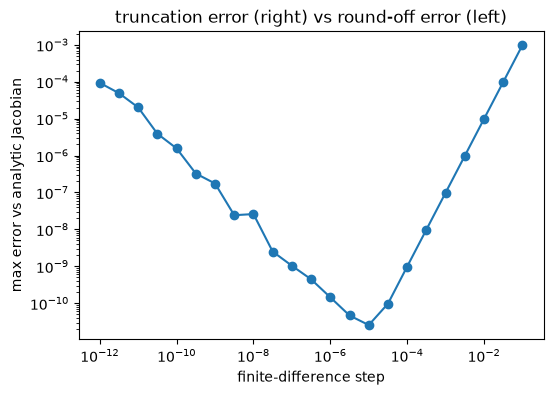

In [5]:
eps_list = np.logspace(-12, -1, 23)
errs = [np.abs(numeric_jacobian(hand_pos, q, e) - jacp[:, :7]).max() for e in eps_list]
plt.figure(figsize=(6, 4)); plt.loglog(eps_list, errs, "o-")
plt.xlabel("finite-difference step"); plt.ylabel("max error vs analytic Jacobian")
plt.title("truncation error (right) vs round-off error (left)"); plt.show()